# Klasifikasi Citra dengan Ekstraksi Fitur GLCM
Proyek UAS Machine Learning - TK34005

Notebook ini berisi seluruh eksperimen: membaca dataset (`train` / `valid` / `test`),
preprocessing, ekstraksi fitur, pemilihan set fitur, k-fold cross validation, tuning
hyperparameter, evaluasi akhir pada data test, dan penyimpanan model untuk `app.py`.

**Struktur folder (jalankan notebook dari folder `UAS/`):**
```
UAS/
├── dataset_citra.ipynb
├── app.py
├── requirements.txt
├── models/      <- diisi otomatis oleh notebook ini
└── Dataset/
    ├── train/<nama_kelas>/gambar.jpg
    ├── valid/<nama_kelas>/gambar.jpg
    └── test/<nama_kelas>/gambar.jpg
```
**Peran tiap data:** `train` untuk melatih dan k-fold, `valid` untuk memilih set fitur dan
hyperparameter, `test` hanya dipakai sekali di akhir untuk melaporkan performa.

## 1. Import library dan konfigurasi

In [ ]:
import time, warnings
from pathlib import Path
warnings.filterwarnings("ignore", message=".*probability.*", category=FutureWarning)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import joblib
import sklearn, skimage
from skimage.feature import hog
try:
    from skimage.feature import graycomatrix, graycoprops
except ImportError: 
    from skimage.feature import greycomatrix as graycomatrix, greycoprops as graycoprops
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, ParameterGrid
from sklearn.metrics import (precision_recall_fscore_support, accuracy_score,
                             confusion_matrix, classification_report)

ROOT = Path.cwd()
DIR_DATASET = ROOT / "Dataset"
DIR_MODELS = ROOT / "models"

K_FOLD = 5 
SEED = 42
SET_FITUR = "auto"
MAKS_PER_KELAS = None 

## 2. Fungsi preprocessing dan ekstraksi fitur
Tiga kelompok fitur, supaya pengaruh masing-masing dapat dibandingkan:

| Kelompok | Isi |
|---|---|
| `glcm` | Contrast, Correlation, Energy, Homogeneity pada 2 jarak x 4 sudut |
| `warna` | Histogram HSV, proporsi piksel merah dan gelap |
| `bentuk` | HOG dan Hu Moments |

Kode di sel ini sama persis dengan yang ada di `app.py`, supaya fitur saat training dan saat
prediksi identik.

In [ ]:
VERSI_FITUR = "glcm-v1"
UKURAN = 128  
LEVEL = 32 
JARAK = (1, 3) 
SUDUT = (0, np.pi / 4, np.pi / 2, 3 * np.pi / 4)
NAMA_SUDUT = (0, 45, 90, 135)
PROPS = ("contrast", "correlation", "ASM", "homogeneity")
NAMA_PROP = {"ASM": "energy"}


def baca_citra(path):
    """Baca gambar (aman untuk path yang mengandung spasi/karakter non-ASCII)."""
    data = np.fromfile(str(path), dtype=np.uint8)
    img = cv2.imdecode(data, cv2.IMREAD_COLOR)
    if img is None:
        raise ValueError(f"Gambar tidak dapat dibaca: {path}")
    return img


def praproses(img_bgr, ukuran=UKURAN):
    """Resize lalu ubah ke grayscale. Mengembalikan (bgr, gray)."""
    bgr = cv2.resize(img_bgr, (ukuran, ukuran), interpolation=cv2.INTER_AREA)
    return bgr, cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)


def kuantisasi(gray, level=LEVEL):
    return (gray.astype(np.uint16) * level // 256).astype(np.uint8)


def hitung_glcm(gray, level=LEVEL, jarak=JARAK, sudut=SUDUT, symmetric=True):
    return graycomatrix(kuantisasi(gray, level), list(jarak), list(sudut),
                        levels=level, symmetric=symmetric, normed=True)


def homogeneity_kuliah(glcm):
    """sum p(i,j) / (1 + |i-j|). Bentuk (n_jarak, n_sudut)."""
    n = glcm.shape[0]
    i, j = np.indices((n, n))
    return np.einsum("ij,ijkl->kl", 1.0 / (1.0 + np.abs(i - j)), glcm)


def hitung_prop(glcm, p):
    return homogeneity_kuliah(glcm) if p == "homogeneity" else graycoprops(glcm, p)


def fitur_glcm(gray):
    glcm = hitung_glcm(gray)
    nilai, nama = [], []
    for p in PROPS:
        m = hitung_prop(glcm, p)
        for i, d in enumerate(JARAK):
            for j, a in enumerate(NAMA_SUDUT):
                nilai.append(m[i, j])
                nama.append(f"glcm_{NAMA_PROP.get(p, p)}_d{d}_a{a}")
    return np.nan_to_num(np.array(nilai, dtype=float)), nama


def fitur_warna(bgr):
    h, s, v = cv2.split(cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV))
    nilai, nama = [], []
    for kanal, bins, rentang, label in ((h, 12, [0, 180], "h"), (s, 4, [0, 256], "s"), (v, 4, [0, 256], "v")):
        hist = cv2.calcHist([kanal], [0], None, [bins], rentang).ravel()
        hist = hist / (hist.sum() + 1e-9)
        for i, x in enumerate(hist):
            nilai.append(float(x))
            nama.append(f"warna_{label}{i}")
    merah = (((h <= 10) | (h >= 170)) & (s >= 100) & (v >= 60)).mean()
    nilai += [float(merah), float((v < 70).mean())]
    nama += ["warna_frac_merah", "warna_frac_gelap"]
    return np.array(nilai, dtype=float), nama


def fitur_bentuk(gray):
    kecil = cv2.resize(gray, (64, 64), interpolation=cv2.INTER_AREA)
    h = hog(kecil, orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2), block_norm="L2-Hys")
    _, bw = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    hu = cv2.HuMoments(cv2.moments(bw, binaryImage=True)).ravel()
    hu = -np.sign(hu) * np.log10(np.abs(hu) + 1e-30)
    nama = [f"bentuk_hog{i}" for i in range(len(h))] + [f"bentuk_hu{i}" for i in range(7)]
    return np.nan_to_num(np.concatenate([h, hu]).astype(float)), nama


def ekstrak_semua(img_bgr):
    """Praproses + semua fitur. Mengembalikan (vektor, nama_fitur, bgr, gray)."""
    bgr, gray = praproses(img_bgr)
    bagian = [fitur_glcm(gray), fitur_warna(bgr), fitur_bentuk(gray)]
    return (np.concatenate([b[0] for b in bagian]), sum([b[1] for b in bagian], []), bgr, gray)


def pilih_indeks(nama_fitur, kelompok):
    """Indeks kolom untuk kelompok fitur, mis. ('glcm', 'warna')."""
    return [i for i, n in enumerate(nama_fitur) if n.split("_")[0] in kelompok]

## 3. Memahami GLCM dengan contoh dari materi kuliah
Citra 3-bit 3×3 pada slide, GLCM jarak 1 dan sudut 0° (`[0 1]`). Hasil di slide:
Contrast 5,667; Correlation -0,056; Energy 0,222; Homogeneity 0,306.

In [3]:
contoh = np.array([[3, 5, 7],
                   [2, 4, 1],
                   [6, 3, 5]], dtype=np.uint8)
g = graycomatrix(contoh, [1], [0], levels=8, symmetric=False, normed=True)
print("Jumlah pasangan piksel (baris i, kolom j), sebelum dibagi 6:")
print(np.round(g[:, :, 0, 0] * 6).astype(int))
for p in PROPS:
    print(f"{NAMA_PROP.get(p, p):<12}: {float(hitung_prop(g, p)[0, 0]):.3f}")

Jumlah pasangan piksel (baris i, kolom j), sebelum dibagi 6:
[[0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 1 0 0 0]
 [0 0 0 0 0 2 0 0]
 [0 1 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 1]
 [0 0 0 1 0 0 0 0]
 [0 0 0 0 0 0 0 0]]
contrast    : 5.667
correlation : -0.055
energy      : 0.222
homogeneity : 0.306


Nilainya sama dengan perhitungan manual di slide (selisih Correlation hanya karena pembulatan).

## 4. Membaca dataset
Setiap split berisi satu folder per kelas. Nama folder = nama kelas.

In [4]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}
ALIAS = {"train": ["train", "training"], "valid": ["valid", "val", "validation"], "test": ["test", "testing"]}


def cari_folder_split(nama):
    for d in DIR_DATASET.iterdir():
        if d.is_dir() and d.name.lower() in ALIAS[nama]:
            return d
    raise FileNotFoundError(f"Folder '{nama}' tidak ditemukan di {DIR_DATASET}. "
                            "Susun dataset sebagai Dataset/train, Dataset/valid, Dataset/test.")


def muat_split(nama):
    folder = cari_folder_split(nama)
    rnd = np.random.default_rng(SEED)
    paths, labels = [], []
    for k in sorted(p for p in folder.iterdir() if p.is_dir()):
        files = sorted(f for f in k.rglob("*") if f.suffix.lower() in IMG_EXT)
        if MAKS_PER_KELAS and len(files) > MAKS_PER_KELAS:
            files = [files[i] for i in rnd.choice(len(files), MAKS_PER_KELAS, replace=False)]
        paths += files
        labels += [k.name] * len(files)
    if not paths:
        raise RuntimeError(f"Tidak ada gambar di {folder}. Isi dengan folder per kelas: {folder}/<kelas>/<gambar>")
    return paths, np.array(labels)


data = {s: muat_split(s) for s in ("train", "valid", "test")}
tabel = pd.DataFrame({s: pd.Series(data[s][1]).value_counts() for s in data}).fillna(0).astype(int).sort_index()
tabel.loc["TOTAL"] = tabel.sum()
tabel

,train,valid,test
freshripe,704,207,102
freshunripe,501,136,83
overripe,783,229,113
ripe,470,132,52
rotten,1340,388,185
unripe,133,31,27
TOTAL,3931,1123,562


In [5]:
kelas_train = sorted(str(k) for k in set(data["train"][1]))
for s in ("valid", "test"):
    asing = set(data[s][1]) - set(kelas_train)
    if asing:
        print(f"Peringatan: kelas {sorted(asing)} ada di '{s}' tetapi tidak ada di 'train'.")
print("Kelas:", kelas_train)

Kelas: ['freshripe', 'freshunripe', 'overripe', 'ripe', 'rotten', 'unripe']


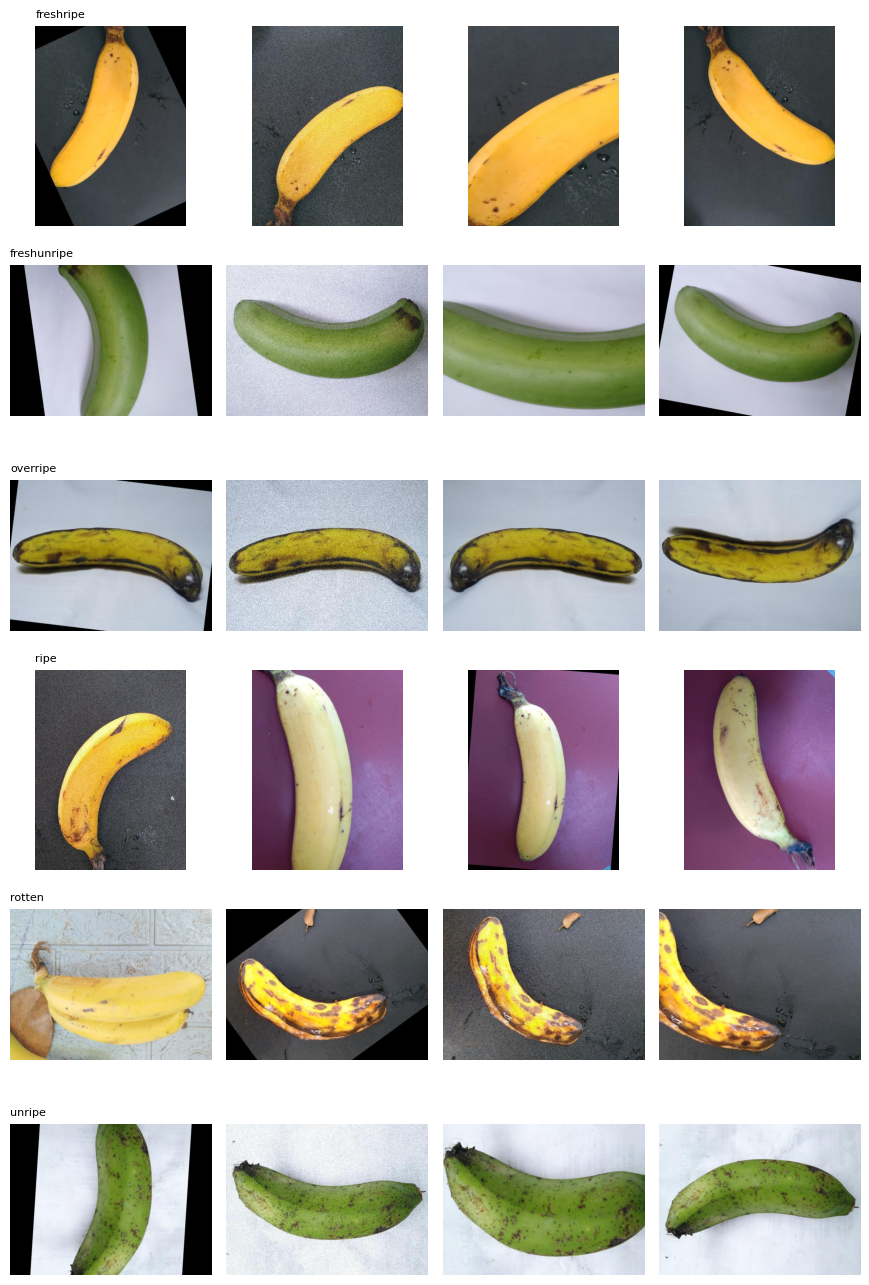

In [ ]:
paths_tr, y_tr_raw = data["train"]
n = 4
fig, axes = plt.subplots(len(kelas_train), n, figsize=(2.2 * n, 2.2 * len(kelas_train)), squeeze=False)
for i, k in enumerate(kelas_train):
    for j, p in enumerate([p for p, l in zip(paths_tr, y_tr_raw) if l == k][:n]):
        axes[i, j].imshow(cv2.cvtColor(baca_citra(p), cv2.COLOR_BGR2RGB))
        axes[i, j].axis("off")
    axes[i, 0].set_title(k, fontsize=8, loc="left")
plt.tight_layout(); plt.show()

## 5. Preprocessing

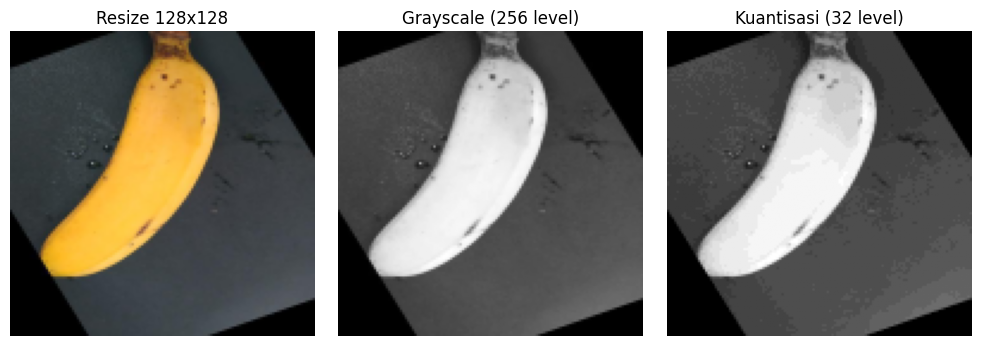

In [7]:
bgr, gray = praproses(baca_citra(paths_tr[0]))
q = kuantisasi(gray)
fig, ax = plt.subplots(1, 3, figsize=(10, 3.4))
ax[0].imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)); ax[0].set_title(f"Resize {UKURAN}x{UKURAN}")
ax[1].imshow(gray, cmap="gray"); ax[1].set_title("Grayscale (256 level)")
ax[2].imshow(q, cmap="gray"); ax[2].set_title(f"Kuantisasi ({LEVEL} level)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## 6. Ekstraksi fitur seluruh data
Waktu ekstraksi dicatat untuk laporan.

In [8]:
NAMA_FITUR = ekstrak_semua(np.tile(np.arange(64, dtype=np.uint8), (64, 1))[:, :, None].repeat(3, axis=2))[1]


def ekstrak_split(paths, labels):
    baris, ok, gagal = [], [], []
    t0 = time.perf_counter()
    for i, p in enumerate(paths):
        try:
            baris.append(ekstrak_semua(baca_citra(p))[0])
            ok.append(i)
        except ValueError:
            gagal.append(p)
    return np.vstack(baris), np.array(labels)[ok], gagal, time.perf_counter() - t0


F, Y, waktu_ekstraksi = {}, {}, {}
for s in ("train", "valid", "test"):
    F[s], Y[s], gagal, waktu_ekstraksi[s] = ekstrak_split(*data[s])
    print(f"{s:<6}: {F[s].shape[0]} citra, {F[s].shape[1]} fitur, {waktu_ekstraksi[s]:.1f} detik"
          + (f" | {len(gagal)} gambar rusak dilewati" if gagal else ""))

total_citra = sum(len(Y[s]) for s in Y)
total_waktu = sum(waktu_ekstraksi.values())
print(f"\nTotal {total_citra} citra | waktu ekstraksi {total_waktu:.2f} detik | rata-rata {total_waktu / total_citra * 1000:.2f} ms per citra")
print({k: sum(n.startswith(k + '_') for n in NAMA_FITUR) for k in ('glcm', 'warna', 'bentuk')})

train : 3931 citra, 385 fitur, 44.7 detik
valid : 1123 citra, 385 fitur, 11.7 detik
test  : 562 citra, 385 fitur, 5.9 detik

Total 5616 citra | waktu ekstraksi 62.23 detik | rata-rata 11.08 ms per citra
{'glcm': 32, 'warna': 22, 'bentuk': 331}


## 7. Fungsi bantu: model dan metrik
Empat algoritma: Naive Bayes, Decision Tree, SVM, dan KNN. Fitur dinormalisasi dengan `StandardScaler`
yang hanya dilatih pada data `train`.

In [9]:
ALGO = ["Naive Bayes", "Decision Tree", "SVM", "KNN"]
FILE_ALGO = {"Naive Bayes": "naive_bayes", "Decision Tree": "decision_tree", "SVM": "svm", "KNN": "knn"}
FITUR_SET = {"GLCM": ["glcm"], "GLCM + Warna": ["glcm", "warna"], "GLCM + Warna + Bentuk": ["glcm", "warna", "bentuk"]}


def buat_svm(params, prob):
    dasar = dict(kernel="rbf", random_state=SEED, **params)
    dasar.setdefault("C", 10)
    if not prob:
        return SVC(**dasar)
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", FutureWarning)
            return SVC(probability=True, **dasar)
    except TypeError: 
        return CalibratedClassifierCV(SVC(**dasar), ensemble=False)


def buat_clf(algo, params=None, prob=False):
    params = dict(params or {})
    if algo == "Naive Bayes":
        return GaussianNB(**params)
    if algo == "Decision Tree":
        return DecisionTreeClassifier(random_state=SEED, **params)
    if algo == "SVM":
        return buat_svm(params, prob)
    if algo == "KNN":
        return KNeighborsClassifier(**({"n_neighbors": 5} | params))
    raise ValueError(algo)


def hitung_metrik(y, pred):
    p, r, f1, _ = precision_recall_fscore_support(y, pred, average="macro", zero_division=0)
    return dict(precision=p, recall=r, f1=f1, akurasi=accuracy_score(y, pred))

## 8. Memilih set fitur
Tiap set fitur dicoba pada keempat algoritma (parameter bawaan): dilatih pada `train`, dinilai pada `valid`.
Set dengan rata-rata F1 tertinggi dipakai (kecuali `SET_FITUR` diisi manual).

In [10]:
hasil = []
for fs, kel in FITUR_SET.items():
    idx = pilih_indeks(NAMA_FITUR, kel)
    sc = StandardScaler().fit(F["train"][:, idx])
    A, B = sc.transform(F["train"][:, idx]), sc.transform(F["valid"][:, idx])
    for algo in ALGO:
        m = buat_clf(algo).fit(A, Y["train"])
        hasil.append(dict(set_fitur=fs, algoritma=algo, jumlah_fitur=len(idx), **hitung_metrik(Y["valid"], m.predict(B))))
df_fs = pd.DataFrame(hasil)
display(df_fs.pivot(index="algoritma", columns="set_fitur", values="f1").reindex(ALGO)[list(FITUR_SET)].round(4))

SET_PAKAI = df_fs.groupby("set_fitur")["f1"].mean().reindex(list(FITUR_SET)).idxmax() if SET_FITUR == "auto" else SET_FITUR
IDX = pilih_indeks(NAMA_FITUR, FITUR_SET[SET_PAKAI])
NAMA_PAKAI = [NAMA_FITUR[i] for i in IDX]
print(f"\nSet fitur yang dipakai: {SET_PAKAI} ({len(IDX)} fitur)")

set_fitur,GLCM,GLCM + Warna,GLCM + Warna + Bentuk
algoritma,,,
Naive Bayes,0.4201,0.6262,0.6007
Decision Tree,0.7168,0.8890,0.8717
SVM,0.7397,0.9499,0.9165
KNN,0.7230,0.8769,0.8215



Set fitur yang dipakai: GLCM + Warna (54 fitur)


In [ ]:
scaler = StandardScaler().fit(F["train"][:, IDX])
Xtr, Xva, Xte = (scaler.transform(F[s][:, IDX]) for s in ("train", "valid", "test"))
ytr, yva, yte = Y["train"], Y["valid"], Y["test"]
KELAS = sorted(str(k) for k in set(ytr))
print(Xtr.shape, Xva.shape, Xte.shape)

(3931, 54) (1123, 54) (562, 54)


## 9. K-fold cross validation pada data train
Dihitung dengan parameter bawaan. Scaler berada di dalam pipeline sehingga dilatih ulang pada
setiap fold (tidak ada kebocoran data).

In [12]:
k = min(K_FOLD, int(pd.Series(ytr).value_counts().min()))
if k < K_FOLD:
    print(f"Peringatan: kelas terkecil hanya punya {k} citra, jumlah fold diturunkan menjadi {k}.")
skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=SEED)
baris = []
for algo in ALGO:
    for f, (a, b) in enumerate(skf.split(F["train"][:, IDX], ytr), 1):
        pipe = Pipeline([("sc", StandardScaler()), ("clf", buat_clf(algo))])
        t0 = time.perf_counter(); pipe.fit(F["train"][a][:, IDX], ytr[a]); t_latih = time.perf_counter() - t0
        t0 = time.perf_counter(); pred = pipe.predict(F["train"][b][:, IDX]); t_pred = time.perf_counter() - t0
        baris.append(dict(algoritma=algo, fold=f, **hitung_metrik(ytr[b], pred), waktu_latih=t_latih, waktu_prediksi=t_pred))
df_cv = pd.DataFrame(baris)

for algo in ALGO:
    t = df_cv[df_cv.algoritma == algo].drop(columns="algoritma").set_index("fold")
    t.index = t.index.astype(str)
    t.loc["Rata-rata"] = t.mean()
    t.index.name = "Eksperimen ke"
    print(f"--- {algo} ---")
    display(t.round(4))

--- Naive Bayes ---


,precision,recall,f1,akurasi,waktu_latih,waktu_prediksi
Eksperimen ke,,,,,,
1,0.6535,0.7175,0.6417,0.6734,0.0109,0.0025
2,0.6210,0.6726,0.6104,0.6399,0.0100,0.0022
3,0.6503,0.7277,0.6445,0.6667,0.0094,0.0019
4,0.6573,0.7141,0.6463,0.6705,0.0091,0.0017
5,0.6241,0.6683,0.6120,0.6450,0.0089,0.0018
Rata-rata,0.6413,0.7001,0.6310,0.6591,0.0097,0.0020


--- Decision Tree ---


,precision,recall,f1,akurasi,waktu_latih,waktu_prediksi
Eksperimen ke,,,,,,
1,0.8941,0.8927,0.8927,0.9022,0.1071,0.0016
2,0.9036,0.8877,0.8948,0.9046,0.1312,0.0014
3,0.8764,0.8713,0.8738,0.8919,0.1070,0.0014
4,0.8789,0.8992,0.8880,0.8982,0.1138,0.0014
5,0.8683,0.8644,0.8661,0.8855,0.1007,0.0014
Rata-rata,0.8843,0.8831,0.8831,0.8965,0.1120,0.0014


--- SVM ---


,precision,recall,f1,akurasi,waktu_latih,waktu_prediksi
Eksperimen ke,,,,,,
1,0.9618,0.9505,0.9559,0.9632,0.1002,0.0545
2,0.9398,0.9139,0.9250,0.9427,0.0995,0.0556
3,0.9473,0.9240,0.9345,0.9478,0.1104,0.0562
4,0.9301,0.9429,0.9357,0.9453,0.0991,0.0556
5,0.9341,0.9445,0.9391,0.9466,0.0996,0.0577
Rata-rata,0.9426,0.9352,0.9380,0.9491,0.1018,0.0559


--- KNN ---


,precision,recall,f1,akurasi,waktu_latih,waktu_prediksi
Eksperimen ke,,,,,,
1,0.8939,0.8652,0.8762,0.9034,0.0080,0.0078
2,0.9034,0.8293,0.8481,0.9071,0.0085,0.0073
3,0.9102,0.8680,0.8834,0.9186,0.0084,0.0089
4,0.8918,0.8647,0.8738,0.8995,0.0085,0.0094
5,0.9194,0.8827,0.8979,0.9148,0.0082,0.0083
Rata-rata,0.9038,0.8620,0.8759,0.9087,0.0083,0.0083


## 10. Tuning hyperparameter pada data valid
Grid kecil untuk tiap algoritma. Parameter terbaik dipilih berdasarkan F1-score pada `valid`.

In [13]:
GRID = {
    "Naive Bayes": {"var_smoothing": [1e-9, 1e-8, 1e-7, 1e-6, 1e-5, 1e-3]},
    "Decision Tree": {"max_depth": [None, 5, 10, 20], "min_samples_leaf": [1, 3, 5]},
    "SVM": {"C": [1, 10, 100], "gamma": ["scale", 0.001, 0.01]},
    "KNN": {"n_neighbors": [3, 5, 7, 9, 11], "weights": ["uniform", "distance"]},
}
terbaik_param, ringkas_tuning = {}, []
for algo in ALGO:
    skor = []
    for params in ParameterGrid(GRID[algo]):
        m = buat_clf(algo, params).fit(Xtr, ytr)
        skor.append((hitung_metrik(yva, m.predict(Xva))["f1"], params))
    f1_best, p_best = max(skor, key=lambda x: x[0])
    terbaik_param[algo] = p_best
    ringkas_tuning.append(dict(algoritma=algo, f1_valid=f1_best, parameter_terbaik=p_best))
df_tuning = pd.DataFrame(ringkas_tuning)
df_tuning.round(4)

,algoritma,f1_valid,parameter_terbaik
0,Naive Bayes,0.6279,{'var_smoothing': 1e-06}
1,Decision Tree,0.9057,"{'max_depth': 10, 'min_samples_leaf': 5}"
2,SVM,0.9512,"{'C': 100, 'gamma': 0.01}"
3,KNN,0.8943,"{'n_neighbors': 5, 'weights': 'distance'}"


## 11. Evaluasi akhir pada data test
Model dengan parameter terbaik dilatih pada `train`, lalu diuji **sekali** pada `test`.
Dicatat Precision, Recall, F1-score (macro), Akurasi, waktu pelatihan, dan waktu prediksi.

In [ ]:
modeli, rows, cms, preds = {}, [], {}, {}
for algo in ALGO:
    p = terbaik_param[algo]
    m = buat_clf(algo, p) 
    t0 = time.perf_counter(); m.fit(Xtr, ytr); t_latih = time.perf_counter() - t0
    t0 = time.perf_counter(); pred = m.predict(Xte); t_pred = time.perf_counter() - t0
    met = hitung_metrik(yte, pred)
    rows.append(dict(algoritma=algo, **met, waktu_latih=t_latih, waktu_prediksi=t_pred))
    cms[algo] = confusion_matrix(yte, pred, labels=KELAS)
    preds[algo] = pred
    modeli[algo] = buat_clf(algo, p, prob=True).fit(Xtr, ytr) 

df_test = pd.DataFrame(rows).merge(df_tuning[["algoritma", "f1_valid"]], on="algoritma")
display(df_test.round(4))

,algoritma,precision,recall,f1,akurasi,waktu_latih,waktu_prediksi,f1_valid
0,Naive Bayes,0.6081,0.6471,0.5933,0.6335,0.0051,0.0009,0.6279
1,Decision Tree,0.8813,0.8395,0.8553,0.8915,0.1203,0.0003,0.9057
2,SVM,0.9495,0.9443,0.9464,0.9591,0.1332,0.0355,0.9512
3,KNN,0.9004,0.8860,0.8927,0.9217,0.0016,0.0053,0.8943


### 11.1 Confusion matrix

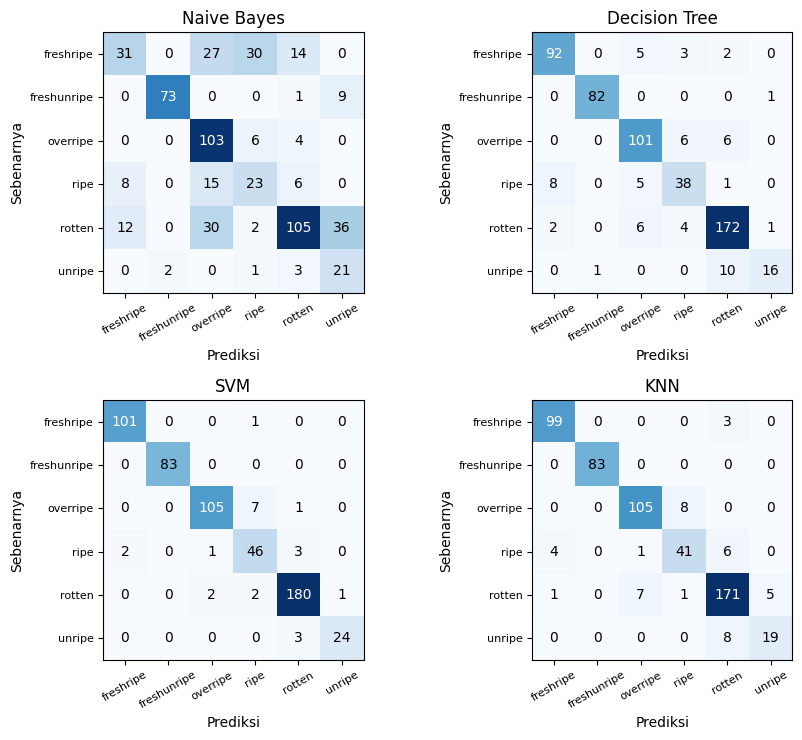

In [15]:
besar = len(KELAS) > 12
fig, axes = plt.subplots(2, 2, figsize=(13, 11) if besar else (9, 7.5))
for ax, algo in zip(axes.ravel(), ALGO):
    cm = cms[algo]
    ax.imshow(cm / cm.sum(axis=1, keepdims=True).clip(min=1) if besar else cm, cmap="Blues")
    ax.set_xticks(range(len(KELAS))); ax.set_yticks(range(len(KELAS)))
    ax.set_xticklabels(KELAS, rotation=90 if besar else 30, fontsize=5 if besar else 8)
    ax.set_yticklabels(KELAS, fontsize=5 if besar else 8)
    if not besar:
        for i in range(len(KELAS)):
            for j in range(len(KELAS)):
                ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_title(algo); ax.set_xlabel("Prediksi"); ax.set_ylabel("Sebenarnya")
plt.tight_layout(); plt.show()

In [16]:
terbaik = df_test.sort_values(["f1_valid", "f1"], ascending=False).iloc[0].algoritma
print(f"Model terbaik (berdasarkan F1 pada data valid): {terbaik}\n")
print(classification_report(yte, preds[terbaik], zero_division=0))

Model terbaik (berdasarkan F1 pada data valid): SVM

              precision    recall  f1-score   support

   freshripe       0.98      0.99      0.99       102
 freshunripe       1.00      1.00      1.00        83
    overripe       0.97      0.93      0.95       113
        ripe       0.82      0.88      0.85        52
      rotten       0.96      0.97      0.97       185
      unripe       0.96      0.89      0.92        27

    accuracy                           0.96       562
   macro avg       0.95      0.94      0.95       562
weighted avg       0.96      0.96      0.96       562



## 12. Kesimpulan otomatis
Ringkasan berikut dihitung dari hasil di atas. Analisis lengkap (mengapa algoritma tertentu unggul,
pengaruh fitur warna dan bentuk, kelas yang sering tertukar) ditulis di laporan.

In [17]:
cm_t = cms[terbaik].copy(); np.fill_diagonal(cm_t, 0)
i, j = np.unravel_index(cm_t.argmax(), cm_t.shape)
tercepat = df_test.sort_values("waktu_latih").iloc[0]
r = df_test.set_index("algoritma").loc[terbaik]
print(f"Set fitur dipakai        : {SET_PAKAI}")
print(f"Model terbaik            : {terbaik} (F1 test = {r.f1:.4f}, akurasi test = {r.akurasi:.4f})")
print(f"Pelatihan tercepat       : {tercepat.algoritma} ({tercepat.waktu_latih:.4f} s)")
if cm_t.max() > 0:
    print(f"Kesalahan tersering      : '{KELAS[i]}' diprediksi sebagai '{KELAS[j]}' ({cm_t.max()} citra)")
print("\nF1 per set fitur (rata-rata 4 algoritma, data valid):")
print(df_fs.groupby("set_fitur")["f1"].mean().reindex(list(FITUR_SET)).round(4).to_string())

Set fitur dipakai        : GLCM + Warna
Model terbaik            : SVM (F1 test = 0.9464, akurasi test = 0.9591)
Pelatihan tercepat       : KNN (0.0016 s)
Kesalahan tersering      : 'overripe' diprediksi sebagai 'ripe' (7 citra)

F1 per set fitur (rata-rata 4 algoritma, data valid):
set_fitur
GLCM                     0.6499
GLCM + Warna             0.8355
GLCM + Warna + Bentuk    0.8026


## 13. Menyimpan model
Disimpan ke folder `models/`: `scaler.joblib` dan satu file untuk tiap algoritma.
Metadata (parameter, metrik, confusion matrix, informasi dataset) ikut disimpan sebagai atribut
`info_` pada masing-masing objek agar `app.py` dapat menampilkannya tanpa file tambahan.

In [18]:
DIR_MODELS.mkdir(exist_ok=True)
rata_ms = total_waktu / total_citra * 1000
scaler.info_ = dict(
    versi_fitur=VERSI_FITUR, set_fitur=SET_PAKAI, nama_fitur=NAMA_PAKAI, kelas=KELAS,
    ukuran=UKURAN, level_glcm=LEVEL, jarak_glcm=list(JARAK), sudut_glcm=list(NAMA_SUDUT),
    jumlah_per_split={s: {k: int(v) for k, v in pd.Series(Y[s]).value_counts().sort_index().items()} for s in Y},
    waktu_ekstraksi_total=total_waktu, waktu_ekstraksi_rata2_ms=rata_ms, k_fold=k,
    perbandingan_set_fitur=df_fs.groupby("set_fitur")["f1"].mean().to_dict(),
    versi_lib=dict(sklearn=sklearn.__version__, skimage=skimage.__version__, opencv=cv2.__version__))
joblib.dump(scaler, DIR_MODELS / "scaler.joblib", compress=3)

for algo in ALGO:
    m = modeli[algo]
    t = df_test.set_index("algoritma").loc[algo]
    cv = df_cv[df_cv.algoritma == algo]
    m.info_ = dict(
        algoritma=algo, parameter=terbaik_param[algo], terbaik=(algo == terbaik), kelas=KELAS, set_fitur=SET_PAKAI,
        f1_valid=float(t.f1_valid), f1_cv=float(cv.f1.mean()), akurasi_cv=float(cv.akurasi.mean()),
        precision=float(t.precision), recall=float(t.recall), f1=float(t.f1), akurasi=float(t.akurasi),
        waktu_latih=float(t.waktu_latih), waktu_prediksi=float(t.waktu_prediksi),
        confusion=cms[algo].tolist())
    joblib.dump(m, DIR_MODELS / f"{FILE_ALGO[algo]}.joblib", compress=3)
    print(f"disimpan: models/{FILE_ALGO[algo]}.joblib")
print("disimpan: models/scaler.joblib")

disimpan: models/naive_bayes.joblib
disimpan: models/decision_tree.joblib
disimpan: models/svm.joblib
disimpan: models/knn.joblib
disimpan: models/scaler.joblib


### Uji muat ulang (memastikan file model dapat dipakai)

In [19]:
sc2 = joblib.load(DIR_MODELS / "scaler.joblib")
idx2 = [NAMA_FITUR.index(n) for n in sc2.info_["nama_fitur"]]
contoh_path = data["test"][0][0]
vek = ekstrak_semua(baca_citra(contoh_path))[0]
x = sc2.transform(vek[idx2].reshape(1, -1))
print("Citra:", contoh_path.name, "| kelas sebenarnya:", data["test"][1][0])
for algo in ALGO:
    m2 = joblib.load(DIR_MODELS / f"{FILE_ALGO[algo]}.joblib")
    pr = m2.predict_proba(x)[0]
    print(f"{algo:<14} -> {m2.classes_[pr.argmax()]} ({pr.max():.1%})")

Citra: musa-acuminata-banana-ad772802-394a-11ec-996c-d8c4975e38aa_jpg.rf.8efc70ac75d64196b8c186a512302743.jpg | kelas sebenarnya: freshripe
Naive Bayes    -> freshripe (88.8%)
Decision Tree  -> freshripe (100.0%)
SVM            -> freshripe (98.1%)
KNN            -> freshripe (100.0%)


Model sudah siap. Jalankan aplikasi dari terminal di folder `UAS/`: `streamlit run app.py`